# Разведочный анализ данных (EDA) — погода в Кишинёве, 2015–2025

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

**Охваченные этапы жизненного цикла Data Science:** шаг 2 (сбор данных), шаг 3 (очистка и предобработка), шаг 4 (EDA).

**Основная задача:** по метеоданным сегодняшнего дня предсказать, **выпадут ли завтра значимые осадки (≥ 1 мм)**.
Порог 1 мм — стандартный порог ВМО (WMO) для «дня с осадками».

**Источник данных:** архив Open-Meteo (реанализ ERA5, ECMWF), ближайший к Кишинёву узел сетки (47.07° с. ш., 28.83° в. д., 48 м). Суточные данные, 01.01.2015 – 31.12.2025.
Данные загружены в хранилище PostgreSQL на **этапе 1** (ноутбук `00_DWH_Etap1.ipynb`) и получены отсюда запросом `sql/04_daily.sql`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_daily, sql_file
PROCESSED = ROOT / "data" / "processed" / "chisinau_daily_clean.csv"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET = "#E0A030", "#2B6CB0"   # colours for the "no rain" / "rain" classes

def save(name):
    plt.savefig(FIG / f"{name}.png")
    plt.show()

pd.set_option("display.max_columns", 40, "display.width", 160)

## 1. Загрузка и описание набора данных

In [2]:
df = load_daily("chisinau")          # query sql/04_daily.sql to the PostgreSQL warehouse
print(f"Размер: {df.shape[0]} наблюдений (дней) x {df.shape[1]} столбцов")
print(f"Период: {df.date.min().date()} — {df.date.max().date()}")
df.head()

Размер: 4018 наблюдений (дней) x 27 столбцов
Период: 2015-01-01 — 2025-12-31


,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,dew_point_2m_mean,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,pressure_msl_mean,pressure_msl_max,pressure_msl_min,cloud_cover_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,et0_fao_evapotranspiration,vapour_pressure_deficit_max,soil_moisture_0_to_7cm_mean
0,2015-01-01,71,-0.6,-14.6,-8.2,-13.1,-12.0,0.9,0.4,0.42,4.0,75.0,92.0,52.0,1029.7,1034.1,1026.4,62.0,14.2,29.5,290.0,3.98,25990.51,30874.54,0.45,0.23,0.319
1,2015-01-02,71,2.0,-1.2,0.5,-3.8,-1.6,1.1,0.8,0.21,4.0,86.0,94.0,75.0,1022.9,1026.0,1017.1,88.0,15.5,32.4,289.0,4.23,27295.59,30931.22,0.47,0.16,0.325
2,2015-01-03,3,4.1,-1.5,1.8,-3.2,-2.3,0.0,0.0,0.00,0.0,74.0,86.0,64.0,1017.5,1019.2,1015.2,60.0,22.2,46.4,290.0,5.05,28800.00,30993.39,0.91,0.29,0.338
3,2015-01-04,71,2.3,-3.7,-0.2,-4.7,-3.8,0.0,0.0,0.07,0.0,77.0,84.0,67.0,1008.9,1014.9,1005.9,82.0,18.9,38.2,272.0,3.49,8104.81,31060.88,0.63,0.24,0.343
4,2015-01-05,73,1.8,-2.2,-0.1,-5.5,-3.4,2.0,0.2,1.40,6.0,78.0,82.0,75.0,1010.2,1014.3,1008.1,67.0,24.2,55.4,297.0,3.47,10498.59,31133.53,0.68,0.17,0.336


### 1.1 Словарь данных (признаки / features)

Относим каждый признак к типу данных — это требование главы 1 шаблона (пп. 1.1.1–1.1.2).

In [3]:
data_dict = pd.DataFrame([
    ("date",                        "Дата наблюдения",                           "—",      "Временной"),
    ("weather_code",                "Код погоды ВМО (тип погоды)",               "код",    "Категориальный номинальный"),
    ("temperature_2m_max",          "Максимальная температура на 2 м",           "°C",     "Числовой непрерывный"),
    ("temperature_2m_min",          "Минимальная температура на 2 м",            "°C",     "Числовой непрерывный"),
    ("temperature_2m_mean",         "Средняя температура на 2 м",                "°C",     "Числовой непрерывный"),
    ("apparent_temperature_mean",   "Средняя ощущаемая температура",             "°C",     "Числовой непрерывный"),
    ("dew_point_2m_mean",           "Средняя точка росы",                        "°C",     "Числовой непрерывный"),
    ("precipitation_sum",           "Сумма осадков",                             "мм",     "Числовой непрерывный"),
    ("rain_sum",                    "Сумма дождя",                               "мм",     "Числовой непрерывный"),
    ("snowfall_sum",                "Сумма снегопада",                           "см",     "Числовой непрерывный"),
    ("precipitation_hours",         "Часы с осадками",                           "ч",      "Числовой дискретный"),
    ("relative_humidity_2m_mean",   "Средняя относительная влажность",           "%",      "Числовой непрерывный"),
    ("relative_humidity_2m_max",    "Максимальная относительная влажность",      "%",      "Числовой непрерывный"),
    ("relative_humidity_2m_min",    "Минимальная относительная влажность",       "%",      "Числовой непрерывный"),
    ("pressure_msl_mean",           "Среднее давление на уровне моря",           "гПа",    "Числовой непрерывный"),
    ("pressure_msl_max",            "Максимальное давление на уровне моря",      "гПа",    "Числовой непрерывный"),
    ("pressure_msl_min",            "Минимальное давление на уровне моря",       "гПа",    "Числовой непрерывный"),
    ("cloud_cover_mean",            "Средняя облачность",                        "%",      "Числовой непрерывный"),
    ("wind_speed_10m_max",          "Максимальная скорость ветра на 10 м",       "км/ч",   "Числовой непрерывный"),
    ("wind_gusts_10m_max",          "Максимальные порывы ветра",                 "км/ч",   "Числовой непрерывный"),
    ("wind_direction_10m_dominant", "Преобладающее направление ветра",           "°",      "Числовой циклический"),
    ("shortwave_radiation_sum",     "Суммарная солнечная радиация",              "МДж/м²", "Числовой непрерывный"),
    ("sunshine_duration",           "Продолжительность солнечного сияния",       "с",      "Числовой непрерывный"),
    ("daylight_duration",           "Продолжительность светового дня",           "с",      "Числовой непрерывный"),
    ("et0_fao_evapotranspiration",  "Эталонная эвапотранспирация FAO",           "мм",     "Числовой непрерывный"),
    ("vapour_pressure_deficit_max", "Максимальный дефицит упругости пара",       "кПа",    "Числовой непрерывный"),
    ("soil_moisture_0_to_7cm_mean", "Влажность почвы 0–7 см",                    "м³/м³",  "Числовой непрерывный"),
], columns=["Признак", "Описание", "Единица", "Тип данных"])
data_dict

,Признак,Описание,Единица,Тип данных
0,date,Дата наблюдения,—,Временной
1,weather_code,Код погоды ВМО (тип погоды),код,Категориальный номинальный
2,temperature_2m_max,Максимальная температура на 2 м,°C,Числовой непрерывный
3,temperature_2m_min,Минимальная температура на 2 м,°C,Числовой непрерывный
4,temperature_2m_mean,Средняя температура на 2 м,°C,Числовой непрерывный
5,apparent_temperature_mean,Средняя ощущаемая температура,°C,Числовой непрерывный
6,dew_point_2m_mean,Средняя точка росы,°C,Числовой непрерывный
7,precipitation_sum,Сумма осадков,мм,Числовой непрерывный
8,rain_sum,Сумма дождя,мм,Числовой непрерывный
9,snowfall_sum,Сумма снегопада,см,Числовой непрерывный


In [4]:
data_dict["Тип данных"].value_counts()

Тип данных
Числовой непрерывный          23
Временной                      1
Категориальный номинальный     1
Числовой дискретный            1
Числовой циклический           1
Name: count, dtype: int64

### 1.2 Описательная статистика

In [5]:
desc = df.drop(columns="date").describe().T
desc["skew"] = df.drop(columns="date").skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
weather_code,4018.0,27.08,27.81,0.00,3.00,3.00,53.00,75.00,0.33
temperature_2m_max,4018.0,16.46,10.17,-13.70,8.00,16.60,25.30,37.80,-0.10
temperature_2m_min,4018.0,7.47,8.42,-20.90,0.70,7.10,15.08,24.90,-0.12
temperature_2m_mean,4018.0,11.79,9.23,-14.60,4.00,11.65,20.18,31.50,-0.07
apparent_temperature_mean,4018.0,9.62,11.00,-22.20,0.40,9.00,19.40,33.30,0.00
dew_point_2m_mean,4018.0,5.57,7.54,-21.30,0.10,5.80,11.60,21.50,-0.28
precipitation_sum,4018.0,1.41,3.65,0.00,0.00,0.00,0.80,37.10,4.37
rain_sum,4018.0,1.25,3.41,0.00,0.00,0.00,0.60,35.90,4.59
snowfall_sum,4018.0,0.11,0.89,0.00,0.00,0.00,0.00,23.94,15.09
precipitation_hours,4018.0,2.69,4.69,0.00,0.00,0.00,4.00,24.00,2.23


## 2. Качество данных (шаг 3 — очистка и предобработка)

Проверяем: пропуски, дубликаты, непрерывность временного ряда, физическую согласованность и выбросы.

In [6]:
quality = {
    "Пропущенные значения (всего)": int(df.isna().sum().sum()),
    "Дублирующиеся строки": int(df.duplicated().sum()),
    "Дублирующиеся даты": int(df.date.duplicated().sum()),
    "Пропущенные дни календаря": int(len(pd.date_range(df.date.min(), df.date.max())) - df.date.nunique()),
}
pd.Series(quality, name="Количество").to_frame()

,Количество
Пропущенные значения (всего),0
Дублирующиеся строки,0
Дублирующиеся даты,0
Пропущенные дни календаря,0


**Проверки физической согласованности** — правила, которым должны подчиняться метеоданные:

In [7]:
checks = {
    "T_min ≤ T_ср ≤ T_max": ((df.temperature_2m_min <= df.temperature_2m_mean) & (df.temperature_2m_mean <= df.temperature_2m_max)).all(),
    "P_min ≤ P_ср ≤ P_max": ((df.pressure_msl_min <= df.pressure_msl_mean) & (df.pressure_msl_mean <= df.pressure_msl_max)).all(),
    "Влажность в [0, 100] %": df.filter(like="relative_humidity").apply(lambda s: s.between(0, 100)).all().all(),
    "Облачность в [0, 100] %": df.cloud_cover_mean.between(0, 100).all(),
    "Осадки ≥ 0": (df[["precipitation_sum", "rain_sum", "snowfall_sum"]] >= 0).all().all(),
    "Часы с осадками в [0, 24]": df.precipitation_hours.between(0, 24).all(),
    "Точка росы ≤ T_max": (df.dew_point_2m_mean <= df.temperature_2m_max).all(),
    "Солнце ≤ длительность дня": (df.sunshine_duration <= df.daylight_duration + 1).all(),
    "Осадки > 0 ⇒ часы с осадками > 0": ((df.precipitation_sum == 0) | (df.precipitation_hours > 0)).all(),
}
pd.Series(checks, name="Выполнено").to_frame()

,Выполнено
T_min ≤ T_ср ≤ T_max,True
P_min ≤ P_ср ≤ P_max,True
"Влажность в [0, 100] %",True
"Облачность в [0, 100] %",True
Осадки ≥ 0,True
"Часы с осадками в [0, 24]",True
Точка росы ≤ T_max,True
Солнце ≤ длительность дня,True
Осадки > 0 ⇒ часы с осадками > 0,True


**Выбросы (метод IQR):** значение считается выбросом, если оно выходит за интервал $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$.

In [8]:
num = df.drop(columns=["date", "weather_code", "wind_direction_10m_dominant"])
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
outliers = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
out_tbl = pd.DataFrame({"Выбросы": outliers, "%": (outliers / len(df) * 100).round(1)})
out_tbl[out_tbl["Выбросы"] > 0].sort_values("Выбросы", ascending=False)

,Выбросы,%
rain_sum,708,17.6
precipitation_sum,661,16.5
precipitation_hours,329,8.2
snowfall_sum,305,7.6
pressure_msl_min,67,1.7
wind_speed_10m_max,56,1.4
pressure_msl_mean,55,1.4
wind_gusts_10m_max,55,1.4
relative_humidity_2m_max,54,1.3
pressure_msl_max,50,1.2


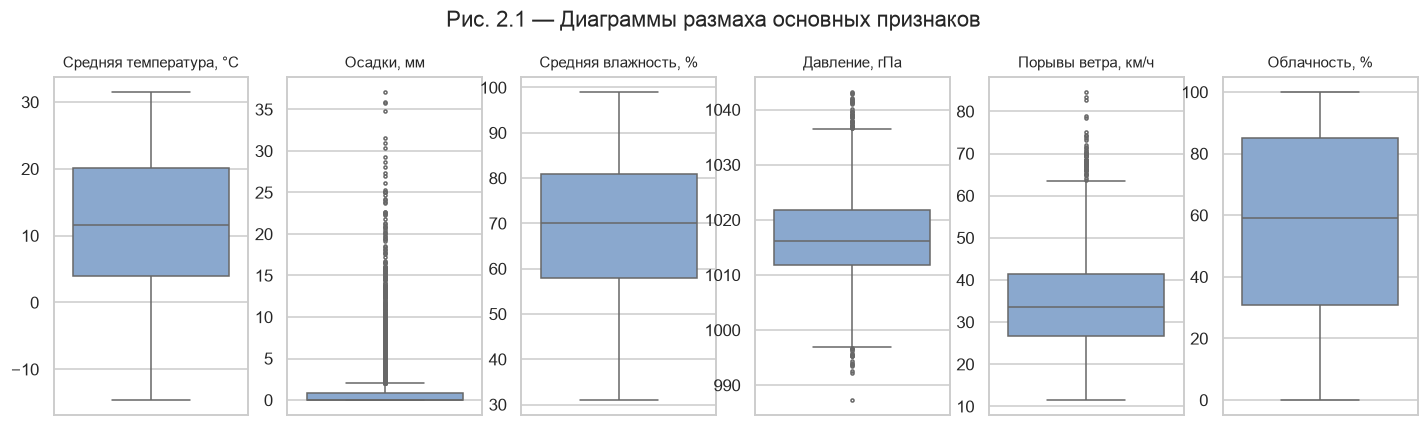

In [9]:
key = ["temperature_2m_mean", "precipitation_sum", "relative_humidity_2m_mean",
       "pressure_msl_mean", "wind_gusts_10m_max", "cloud_cover_mean"]
labels = ["Средняя температура, °C", "Осадки, мм", "Средняя влажность, %",
          "Давление, гПа", "Порывы ветра, км/ч", "Облачность, %"]
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for ax, col, lab in zip(axes, key, labels):
    sns.boxplot(y=df[col], ax=ax, color="#7FA7D9", fliersize=2)
    ax.set_title(lab, fontsize=10); ax.set_ylabel("")
fig.suptitle("Рис. 2.1 — Диаграммы размаха основных признаков", y=1.03)
save("fig_2_1_boxplots")

**Интерпретация.** В данных нет пропусков, дубликатов и пропущенных дней, все физические правила выполняются — этого и следует ожидать от реанализа (ERA5 — это модель, которая ассимилирует наблюдения станций, а не «сырые» данные датчиков).

«Выбросы», найденные методом IQR, **не являются ошибками**: осадки, снегопад и порывы ветра имеют сильно асимметричные распределения — большинство дней без осадков, а ливни редки, но реальны. Поэтому **выбросы не удаляем**: это именно те события, которые мы хотим предсказывать.

> **Замечание для исследования:** то, что данные «слишком чистые», — аргумент для элементов **Noise** и **Bias** главы 2: там мы сами внесём контролируемый шум и искажения, чтобы смоделировать условия реальной метеостанции.

## 3. Целевая переменная: осадки завтра

$$\text{rain\_tomorrow}_t = \begin{cases}1, & \text{precipitation\_sum}_{t+1} \ge 1\text{ мм}\\ 0, & \text{иначе}\end{cases}$$

Последний день ряда (31.12.2025) не имеет «завтра» и исключается.

In [10]:
RAIN_MM = 1.0
df["rain_today"] = (df.precipitation_sum >= RAIN_MM).astype(int)
df["rain_tomorrow"] = (df.precipitation_sum.shift(-1) >= RAIN_MM).astype("float")
df.loc[df.index[-1], "rain_tomorrow"] = np.nan
df = df.dropna(subset=["rain_tomorrow"]).astype({"rain_tomorrow": int})

df["year"] = df.date.dt.year
df["month"] = df.date.dt.month
SEASONS = {12: "Зима", 1: "Зима", 2: "Зима", 3: "Весна", 4: "Весна", 5: "Весна",
           6: "Лето", 7: "Лето", 8: "Лето", 9: "Осень", 10: "Осень", 11: "Осень"}
df["season"] = df.month.map(SEASONS)

balance = df.rain_tomorrow.value_counts().rename({0: "Без осадков (0)", 1: "Осадки ≥ 1 мм (1)"})
pd.DataFrame({"Дней": balance, "%": (balance / len(df) * 100).round(1)})

,Дней,%
rain_tomorrow,,
Без осадков (0),3056,76.1
Осадки ≥ 1 мм (1),961,23.9


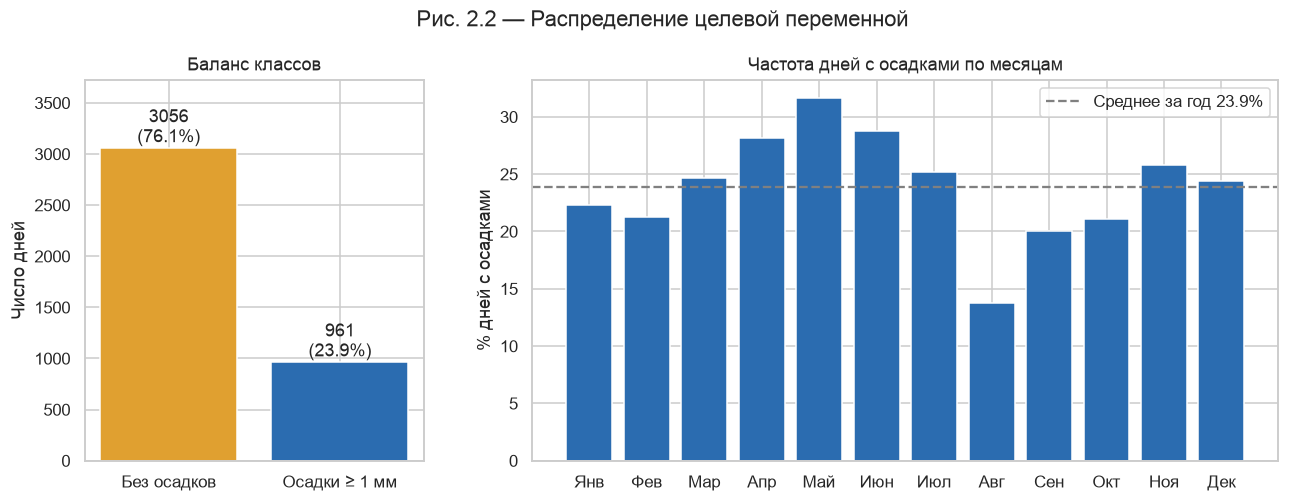

In [11]:
MONTHS = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})
a1.bar(["Без осадков", "Осадки ≥ 1 мм"], balance.values, color=[C_DRY, C_WET])
for i, v in enumerate(balance.values):
    a1.text(i, v + 60, f"{v}\n({v / len(df):.1%})", ha="center")
a1.set_ylabel("Число дней"); a1.set_title("Баланс классов"); a1.set_ylim(0, balance.max() * 1.22)

m = df.groupby("month").rain_tomorrow.mean() * 100
a2.bar(MONTHS, m.values, color=C_WET)
a2.axhline(df.rain_tomorrow.mean() * 100, ls="--", c="gray", label=f"Среднее за год {df.rain_tomorrow.mean():.1%}")
a2.set_ylabel("% дней с осадками"); a2.set_title("Частота дней с осадками по месяцам"); a2.legend()
fig.suptitle("Рис. 2.2 — Распределение целевой переменной", y=1.02)
save("fig_2_2_target")

**Интерпретация.** Классы **несбалансированы** (~1 : 3): осадки ≥ 1 мм выпадают примерно в одном дне из четырёх.
Последствия для моделирования:
- **Accuracy — обманчивая метрика**: модель, которая всегда говорит «дождя не будет», имела бы ~76 % точности и была бы бесполезна. Будем использовать Recall, Precision, F1 и ROC-AUC.
- Дисбаланс обосновывает применение **SMOTE** (один из 6 фундаментальных элементов).
- Частота меняется по месяцам: максимум в апреле–июне (май ≈ 32 % — конвективные дожди весны и начала лета), заметный минимум в **августе (≈ 14 %)** — самом засушливом месяце. Значит, месяц/сезон — полезный признак.

## 4. Одномерный анализ

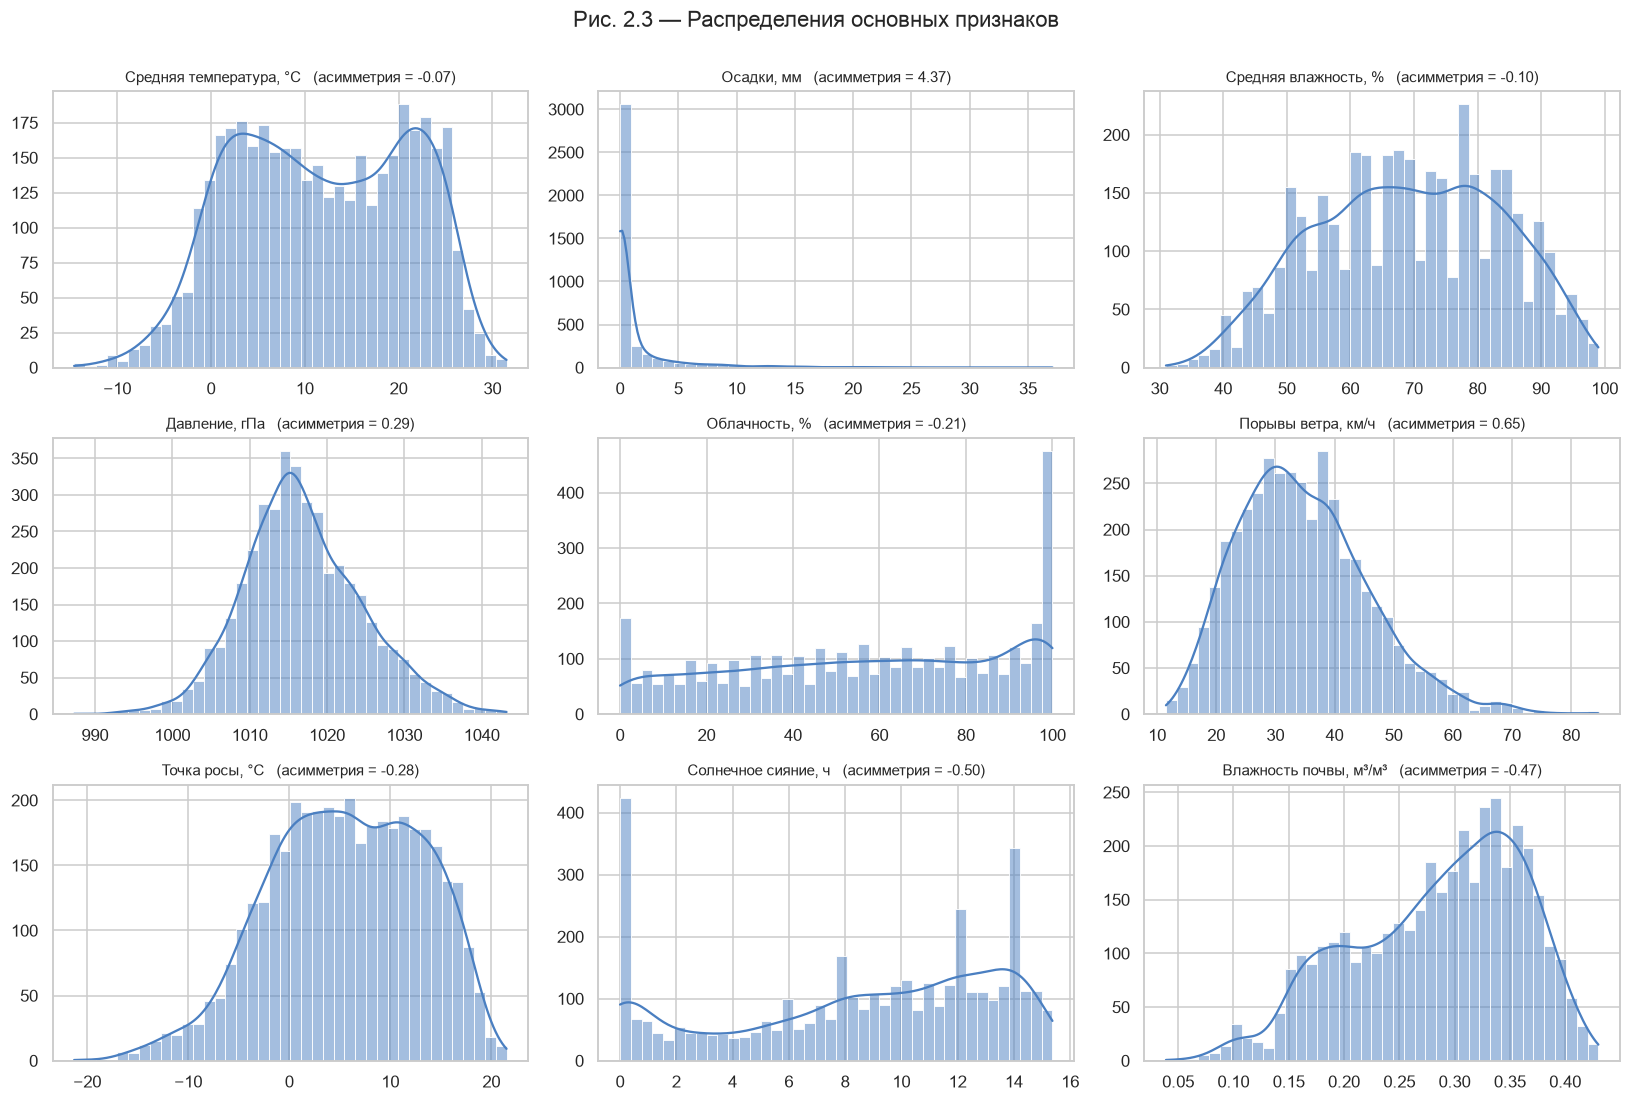

In [12]:
cols = ["temperature_2m_mean", "precipitation_sum", "relative_humidity_2m_mean", "pressure_msl_mean",
        "cloud_cover_mean", "wind_gusts_10m_max", "dew_point_2m_mean", "sunshine_duration", "soil_moisture_0_to_7cm_mean"]
titles = ["Средняя температура, °C", "Осадки, мм", "Средняя влажность, %", "Давление, гПа",
          "Облачность, %", "Порывы ветра, км/ч", "Точка росы, °C", "Солнечное сияние, ч", "Влажность почвы, м³/м³"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c, t in zip(axes.flat, cols, titles):
    s = df[c] / 3600 if c == "sunshine_duration" else df[c]
    sns.histplot(s, bins=40, kde=True, ax=ax, color="#4A7FC1")
    ax.set_title(f"{t}   (асимметрия = {s.skew():.2f})", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Рис. 2.3 — Распределения основных признаков", y=1.0)
plt.tight_layout(); save("fig_2_3_histograms")

In [13]:
precip_pos = df.loc[df.precipitation_sum > 0, "precipitation_sum"]
print(f"Дней совсем без осадков: {(df.precipitation_sum == 0).mean():.1%}")
print(f"Дней с 0 < осадки < 1 мм (следы): {((df.precipitation_sum > 0) & (df.precipitation_sum < 1)).mean():.1%}")
print(f"Медиана осадков в дни с осадками: {precip_pos.median():.1f} мм, максимум: {precip_pos.max():.1f} мм")

Дней совсем без осадков: 55.6%
Дней с 0 < осадки < 1 мм (следы): 20.5%
Медиана осадков в дни с осадками: 1.1 мм, максимум: 37.1 мм


**Интерпретация.**
- **Температура** и **точка росы** имеют бимодальные распределения (зима / лето) — эффект сезонности.
- **Осадки** крайне асимметричны (распределение экспоненциального/гамма-типа): в большинстве дней 0 мм. Поэтому мы решаем задачу **классификации** (будет дождь / не будет), а не регрессии количества осадков.
- **Давление** распределено почти нормально — подходит для классических статистических методов.
- **Облачность** бимодальна (ясное небо vs. сплошная облачность).

### 4.1 Направление ветра (циклический признак)

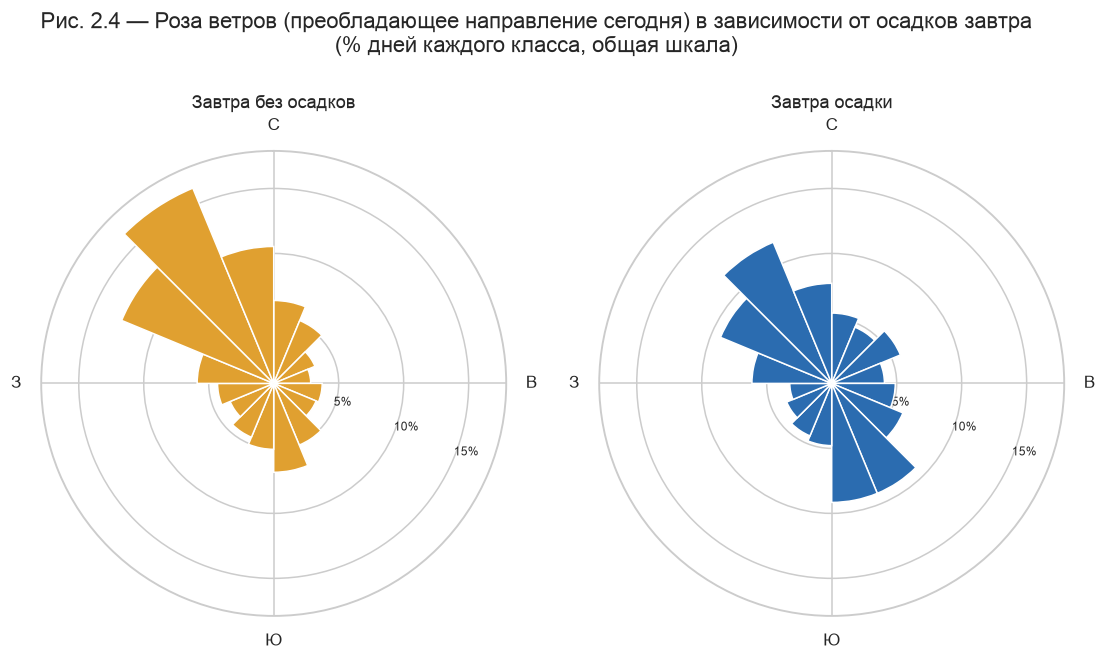

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={"projection": "polar"})
bins = np.deg2rad(np.arange(0, 361, 22.5))
shares = {}
for cls in (0, 1):
    h, _ = np.histogram(np.deg2rad(df.loc[df.rain_tomorrow == cls, "wind_direction_10m_dominant"]), bins=bins)
    shares[cls] = h / h.sum() * 100
rmax = max(v.max() for v in shares.values()) * 1.1
for ax, cls, col, name in zip(axes, [0, 1], [C_DRY, C_WET], ["Завтра без осадков", "Завтра осадки"]):
    ax.bar(bins[:-1], shares[cls], width=np.deg2rad(22.5), align="edge", color=col, edgecolor="white")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_title(name, pad=28)
    ax.set_ylim(0, rmax); ax.set_yticks([5, 10, 15]); ax.set_yticklabels(["5%", "10%", "15%"], fontsize=8)
    ax.set_rlabel_position(112.5)
    ax.set_xticks(np.deg2rad([0, 90, 180, 270])); ax.set_xticklabels(["С", "В", "Ю", "З"])
fig.suptitle("Рис. 2.4 — Роза ветров (преобладающее направление сегодня) в зависимости от осадков завтра\n(% дней каждого класса, общая шкала)", y=1.06)
save("fig_2_4_wind_rose")

**Интерпретация.** Направление ветра — **циклическая** переменная: 359° и 1° почти совпадают, хотя численно сильно различаются.
Для моделирования закодируем его через $\sin(\theta)$ и $\cos(\theta)$.
В Кишинёве преобладают **северо-западные** ветра (≈ 43 % дней), обычно приносящие сухую погоду.
Вероятность осадков на следующий день максимальна при ветре **восточного – юго-восточного – южного направления** (≈ 32 %, влажный воздух со стороны Чёрного моря) и минимальна при северо-западном ветре (≈ 19 %).

In [15]:
SECTORS = ["С–СВ", "СВ–В", "В–ЮВ", "ЮВ–Ю", "Ю–ЮЗ", "ЮЗ–З", "З–СЗ", "СЗ–С"]
sector = pd.cut(df.wind_direction_10m_dominant % 360, bins=np.arange(0, 361, 45), right=False, labels=SECTORS)
pd.DataFrame({"Дней, %": sector.value_counts(normalize=True).sort_index().mul(100).round(1),
              "P(осадки завтра), %": df.groupby(sector, observed=True).rain_tomorrow.mean().mul(100).round(1)})

,"Дней, %","P(осадки завтра), %"
wind_direction_10m_dominant,,
С–СВ,11.5,21.3
СВ–В,7.1,32.9
В–ЮВ,8.1,31.9
ЮВ–Ю,13.5,32.5
Ю–ЮЗ,9.5,23.2
ЮЗ–З,7.7,21.6
З–СЗ,17.8,20.7
СЗ–С,24.8,18.6


## 5. Временной анализ: сезонность и тренды

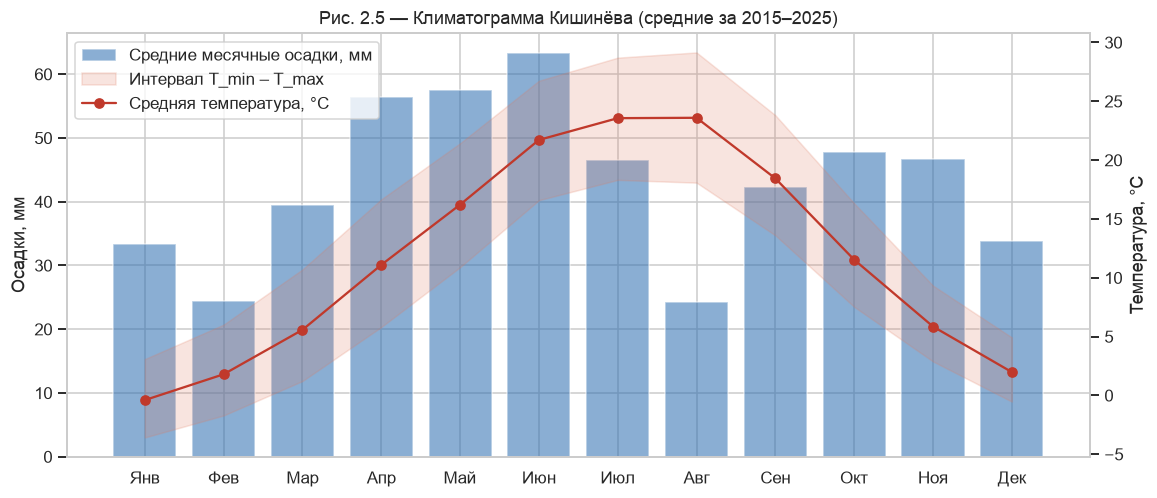

In [16]:
clim = df.groupby("month").agg(tmax=("temperature_2m_max", "mean"), tmin=("temperature_2m_min", "mean"),
                               tmean=("temperature_2m_mean", "mean"))
monthly_precip = df.groupby(["year", "month"]).precipitation_sum.sum().groupby("month").mean()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(MONTHS, monthly_precip.values, color=C_WET, alpha=0.55, label="Средние месячные осадки, мм")
ax1.set_ylabel("Осадки, мм")
ax2 = ax1.twinx()
ax2.fill_between(MONTHS, clim.tmin, clim.tmax, color="#E07A5F", alpha=0.2, label="Интервал T_min – T_max")
ax2.plot(MONTHS, clim.tmean, color="#C0392B", marker="o", label="Средняя температура, °C")
ax2.set_ylabel("Температура, °C"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Рис. 2.5 — Климатограмма Кишинёва (средние за 2015–2025)")
save("fig_2_5_climogram")

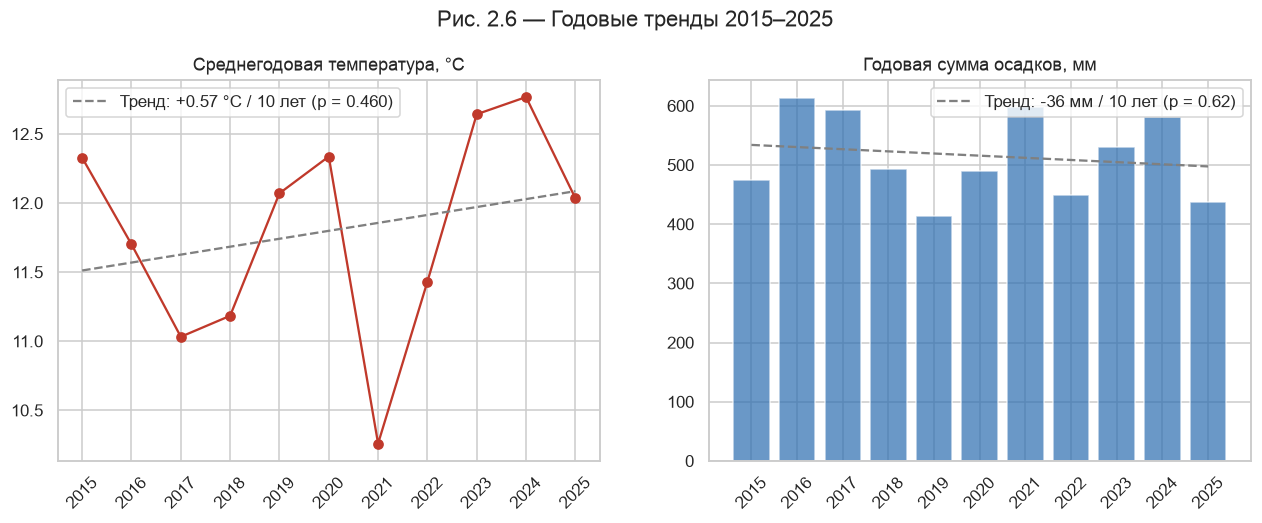

,"T ср., °C","Осадки, мм",Дней с осадками
year,,,
2015,12.3,474.5,84
2016,11.7,613.3,88
2017,11.0,592.0,87
2018,11.2,492.4,84
2019,12.1,413.6,86
2020,12.3,489.4,90
2021,10.3,598.2,115
2022,11.4,449.7,79
2023,12.6,531.0,87


In [17]:
annual = df.groupby("year").agg(t=("temperature_2m_mean", "mean"), p=("precipitation_sum", "sum"),
                                rain_days=("rain_today", "sum"))
annual = annual[annual.index <= 2025]
slope_t = stats.linregress(annual.index, annual.t)
slope_p = stats.linregress(annual.index, annual.p)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
a1.plot(annual.index, annual.t, "o-", color="#C0392B")
a1.plot(annual.index, slope_t.intercept + slope_t.slope * annual.index, "--", color="gray",
        label=f"Тренд: {slope_t.slope * 10:+.2f} °C / 10 лет (p = {slope_t.pvalue:.3f})")
a1.set_title("Среднегодовая температура, °C"); a1.legend()
a2.bar(annual.index, annual.p, color=C_WET, alpha=0.7)
a2.plot(annual.index, slope_p.intercept + slope_p.slope * annual.index, "--", color="gray",
        label=f"Тренд: {slope_p.slope * 10:+.0f} мм / 10 лет (p = {slope_p.pvalue:.2f})")
a2.set_title("Годовая сумма осадков, мм"); a2.legend()
for a in (a1, a2): a.set_xticks(annual.index); a.tick_params(axis="x", rotation=45)
fig.suptitle("Рис. 2.6 — Годовые тренды 2015–2025", y=1.02)
save("fig_2_6_annual_trends")
annual.round(1).rename(columns={"t": "T ср., °C", "p": "Осадки, мм", "rain_days": "Дней с осадками"})

**Интерпретация.**
- Климат Кишинёва **умеренно-континентальный**: тёплое лето (≈ 23.6 °C в июле–августе), холодная зима (≈ −0.4 °C в январе), максимум осадков в апреле–июне (июнь ≈ 63 мм), минимумы в феврале и августе (≈ 24 мм).
- За 11 лет линия регрессии показывает потепление ≈ +0.55 °C за 10 лет, но тренд **статистически не значим** (p ≈ 0.48): 11 точек и большая межгодовая изменчивость (например, холодный 2021 и тёплый 2024) не позволяют делать климатических выводов. Хороший пример **научной осторожности** — линия на графике ещё не доказательство.
- Годовая сумма осадков сильно меняется от года к году (засушливые годы: 2019 ≈ 414 мм, 2025 ≈ 437 мм, 2022 ≈ 450 мм; дождливые: 2016 ≈ 613 мм, 2021 ≈ 598 мм) — без значимого тренда. Для модели это означает, что **распределение данных меняется во времени** (*concept drift*) — аргумент для элемента **RTAP** (адаптация модели в реальном времени).

### 5.1 Инерционность погоды (автокорреляция)

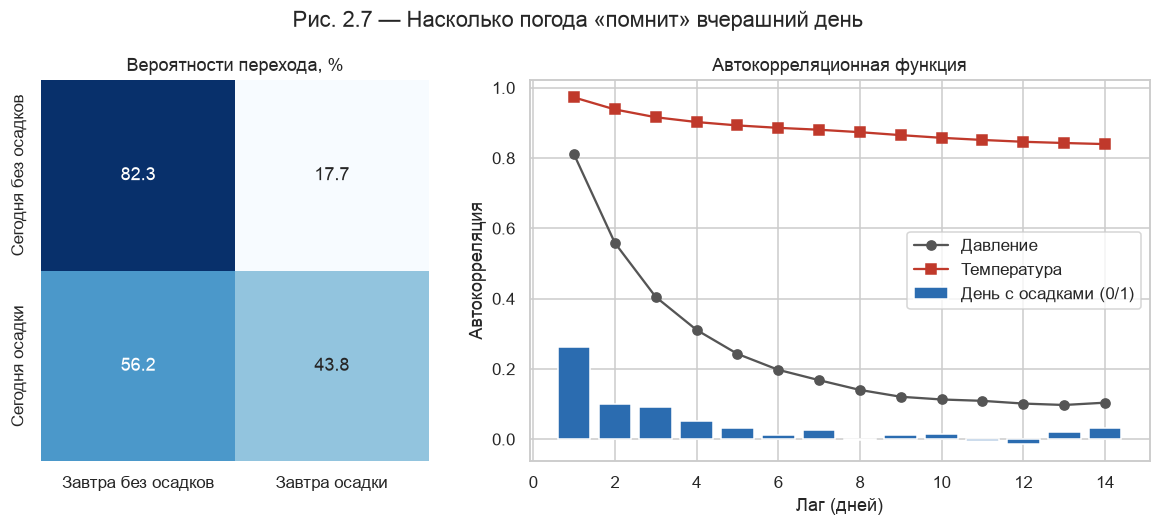

,Завтра без осадков,Завтра осадки
Сегодня без осадков,82.3,17.7
Сегодня осадки,56.2,43.8


In [18]:
trans = pd.crosstab(df.rain_today, df.rain_tomorrow, normalize="index") * 100
trans.index = ["Сегодня без осадков", "Сегодня осадки"]; trans.columns = ["Завтра без осадков", "Завтра осадки"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
sns.heatmap(trans, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=a1)
a1.set_title("Вероятности перехода, %"); a1.set_xlabel(""); a1.set_ylabel("")

lags = range(1, 15)
a2.bar(lags, [df.rain_today.autocorr(l) for l in lags], color=C_WET, label="День с осадками (0/1)")
a2.plot(lags, [df.pressure_msl_mean.autocorr(l) for l in lags], "o-", color="#555", label="Давление")
a2.plot(lags, [df.temperature_2m_mean.autocorr(l) for l in lags], "s-", color="#C0392B", label="Температура")
a2.set_xlabel("Лаг (дней)"); a2.set_ylabel("Автокорреляция"); a2.set_title("Автокорреляционная функция"); a2.legend()
fig.suptitle("Рис. 2.7 — Насколько погода «помнит» вчерашний день", y=1.02)
save("fig_2_7_persistence")
trans.round(1)

**Интерпретация.**
- Если сегодня идёт дождь, вероятность осадков завтра ≈ 44 %, после сухого дня — ≈ 18 %, то есть в **≈ 2.5 раза** выше. У погоды есть «память».
- Память об осадках быстро затухает (автокорреляция падает с 0.26 до 0.10 за 2 дня), давление «помнит» несколько дней (0.81 → 0.17 за неделю), а температура остаётся коррелированной даже через 2 недели (0.84) — в основном из-за сезона.
- Это **наивная базовая модель (baseline)**: «завтра будет как сегодня». Любая ML-модель должна быть лучше неё.

## 6. Двумерный анализ: какие сегодняшние признаки предвещают завтрашние осадки?

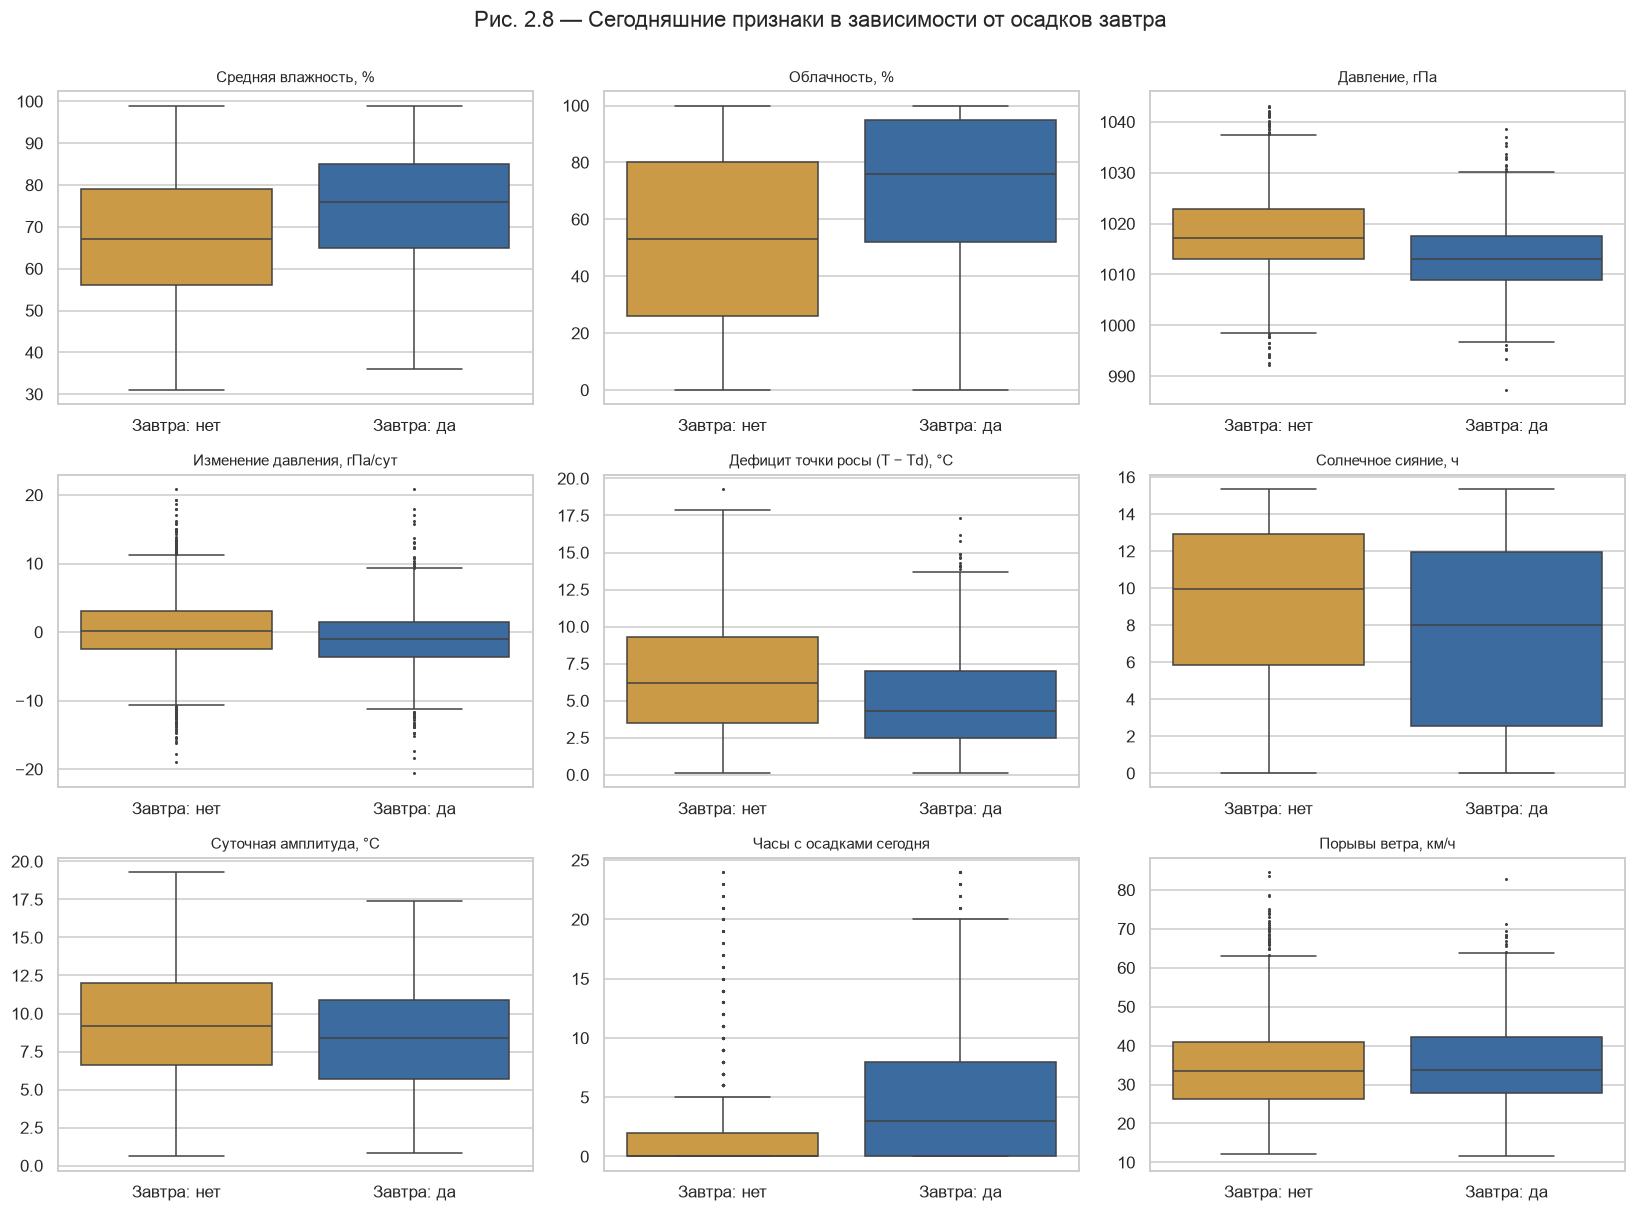

In [19]:
# simple derived features (extended later in the feature engineering step)
df["pressure_change"] = df.pressure_msl_mean.diff()                         # pressure tendency, hPa/day
df["dew_point_depression"] = df.temperature_2m_mean - df.dew_point_2m_mean  # how far the air is from saturation
df["temp_range"] = df.temperature_2m_max - df.temperature_2m_min            # diurnal temperature range

feats = ["relative_humidity_2m_mean", "cloud_cover_mean", "pressure_msl_mean", "pressure_change",
         "dew_point_depression", "sunshine_duration", "temp_range", "precipitation_hours", "wind_gusts_10m_max"]
names = ["Средняя влажность, %", "Облачность, %", "Давление, гПа", "Изменение давления, гПа/сут",
         "Дефицит точки росы (T − Td), °C", "Солнечное сияние, ч", "Суточная амплитуда, °C", "Часы с осадками сегодня", "Порывы ветра, км/ч"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, f, n in zip(axes.flat, feats, names):
    d = df[[f, "rain_tomorrow"]].dropna().copy()
    if f == "sunshine_duration": d[f] = d[f] / 3600
    sns.boxplot(data=d, x="rain_tomorrow", y=f, hue="rain_tomorrow", palette=[C_DRY, C_WET], legend=False, ax=ax, fliersize=1)
    ax.set_xticks([0, 1], ["Завтра: нет", "Завтра: да"]); ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(n, fontsize=10)
fig.suptitle("Рис. 2.8 — Сегодняшние признаки в зависимости от осадков завтра", y=1.0)
plt.tight_layout(); save("fig_2_8_features_vs_target")

**Статистическая проверка различий.** Распределения не нормальные, поэтому используем непараметрический **критерий Манна–Уитни** ($H_0$: распределения двух классов одинаковы).
Размер эффекта — ранговая бисериальная корреляция $r = 1 - \frac{2U}{n_0 n_1}$ (|r| ≈ 0.1 — малый, 0.3 — средний, 0.5 — большой).

In [20]:
test_feats = [c for c in df.columns if c not in ("date", "rain_tomorrow", "rain_today", "year", "month", "season",
                                                 "weather_code", "wind_direction_10m_dominant")]
rows = []
for f in test_feats:
    d = df[[f, "rain_tomorrow"]].dropna()
    a, b = d.loc[d.rain_tomorrow == 0, f], d.loc[d.rain_tomorrow == 1, f]
    u, p = stats.mannwhitneyu(a, b)
    rows.append((f, a.median(), b.median(), p, 1 - 2 * u / (len(a) * len(b))))
mw = (pd.DataFrame(rows, columns=["Признак", "Медиана (завтра: нет)", "Медиана (завтра: да)", "p-value", "Эффект r"])
        .assign(abs_r=lambda t: t["Эффект r"].abs()).sort_values("abs_r", ascending=False).drop(columns="abs_r"))
mw["Значим (α=0.05)"] = np.where(mw["p-value"] < 0.05, "да", "нет")
mw.round(4).reset_index(drop=True)

,Признак,Медиана (завтра: нет),Медиана (завтра: да),p-value,Эффект r,Значим (α=0.05)
0,precipitation_sum,0.0000,0.600,0.0000,0.3714,да
1,precipitation_hours,0.0000,3.000,0.0000,0.3634,да
2,rain_sum,0.0000,0.400,0.0000,0.3598,да
3,pressure_msl_max,1019.4000,1015.200,0.0000,-0.3533,да
4,pressure_msl_min,1015.0000,1010.700,0.0000,-0.3480,да
5,pressure_msl_mean,1017.2000,1013.100,0.0000,-0.3477,да
6,cloud_cover_mean,53.0000,76.000,0.0000,0.3328,да
7,relative_humidity_2m_mean,67.0000,76.000,0.0000,0.2695,да
8,relative_humidity_2m_max,88.0000,93.000,0.0000,0.2658,да
9,dew_point_depression,6.2000,4.300,0.0000,-0.2540,да


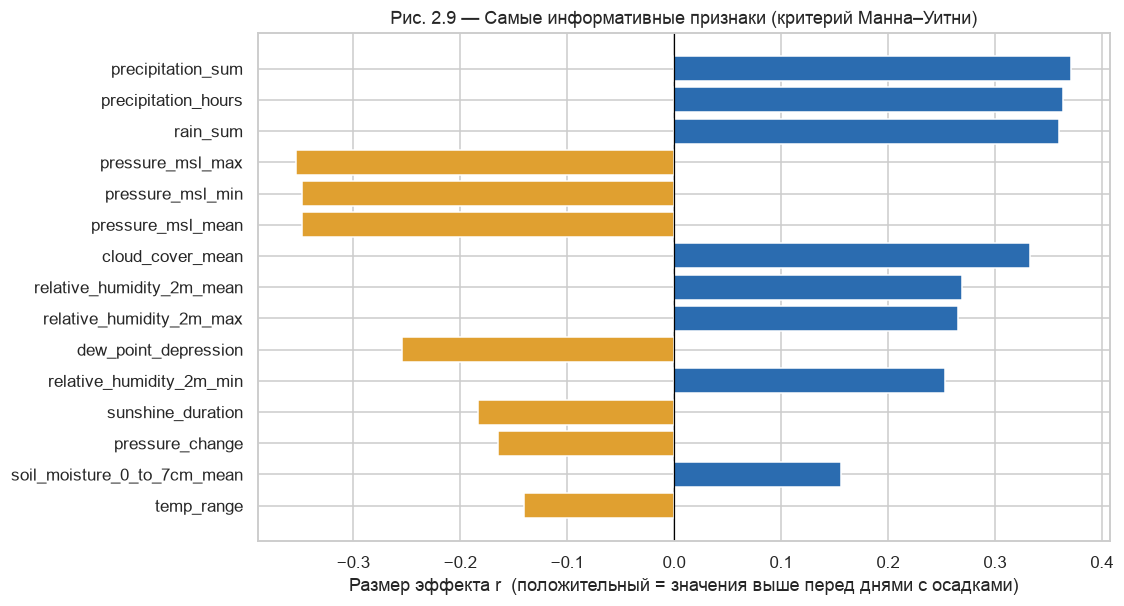

In [21]:
top = mw.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["Признак"], top["Эффект r"], color=np.where(top["Эффект r"] > 0, C_WET, C_DRY))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Размер эффекта r  (положительный = значения выше перед днями с осадками)")
ax.set_title("Рис. 2.9 — Самые информативные признаки (критерий Манна–Уитни)")
save("fig_2_9_effect_sizes")

### 6.1 Корреляционная матрица

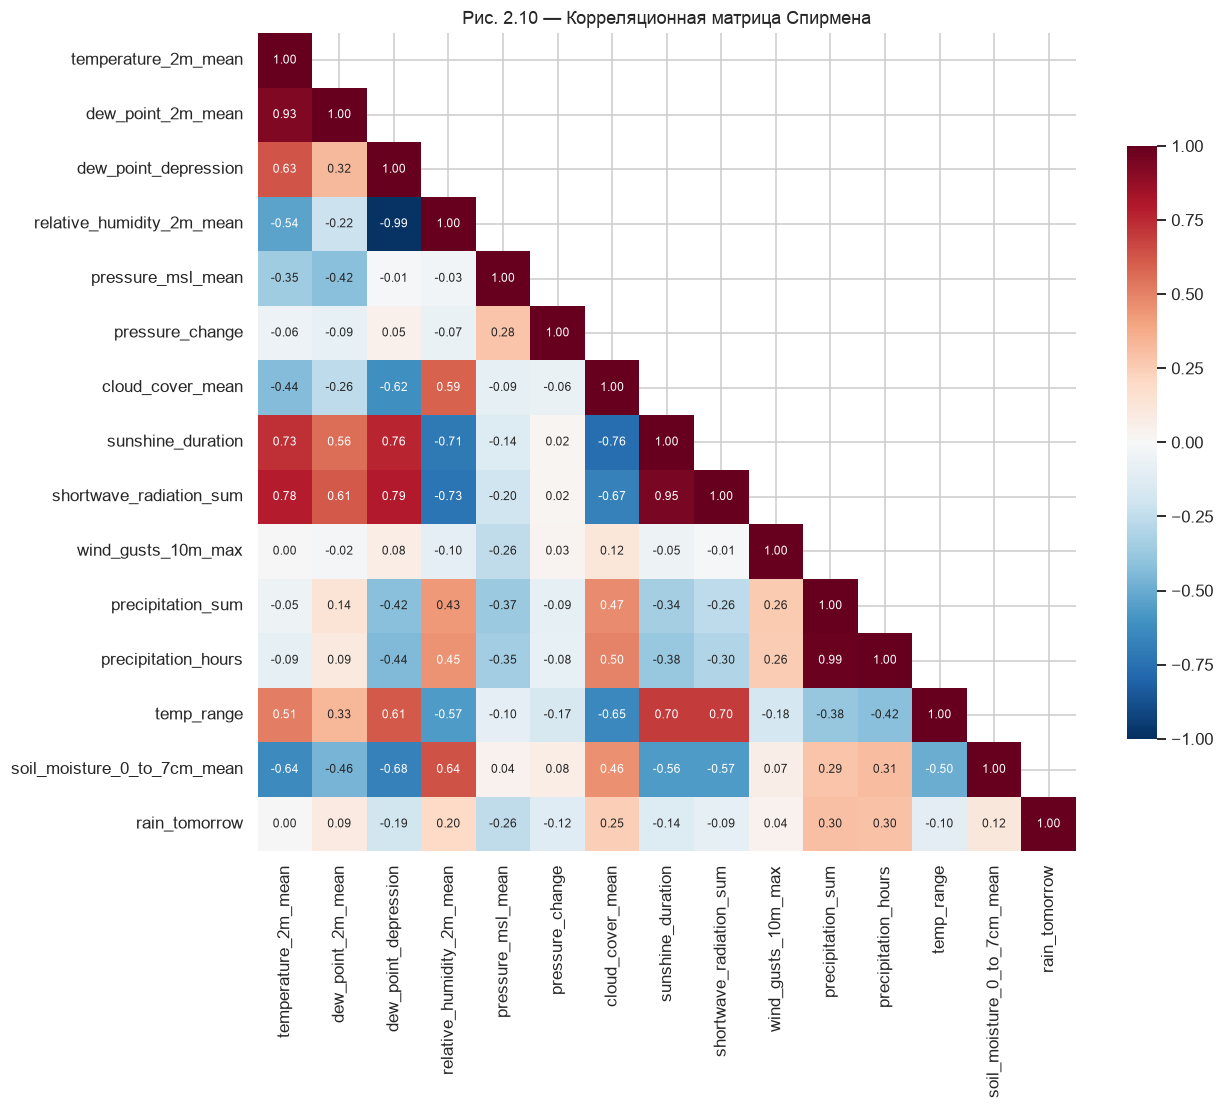

In [22]:
corr_cols = ["temperature_2m_mean", "dew_point_2m_mean", "dew_point_depression", "relative_humidity_2m_mean",
             "pressure_msl_mean", "pressure_change", "cloud_cover_mean", "sunshine_duration", "shortwave_radiation_sum",
             "wind_gusts_10m_max", "precipitation_sum", "precipitation_hours", "temp_range", "soil_moisture_0_to_7cm_mean",
             "rain_tomorrow"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Рис. 2.10 — Корреляционная матрица Спирмена")
save("fig_2_10_correlation")

In [23]:
# nearly redundant feature pairs (|rho| > 0.9) — candidates for removal
full = df[test_feats].corr(method="spearman").abs()
pairs = full.where(np.triu(np.ones(full.shape, dtype=bool), k=1)).stack()
pairs[pairs > 0.9].sort_values(ascending=False).round(3).to_frame("|ρ|")

|ρ|
temperature_2m_mean        apparent_temperature_mean    0.996
relative_humidity_2m_mean  dew_point_depression         0.992
temperature_2m_max         temperature_2m_mean          0.987
precipitation_sum          precipitation_hours          0.986
temperature_2m_max         apparent_temperature_mean    0.982
temperature_2m_min         temperature_2m_mean          0.980
                           apparent_temperature_mean    0.979
pressure_msl_mean          pressure_msl_min             0.977
                           pressure_msl_max             0.969
et0_fao_evapotranspiration vapour_pressure_deficit_max  0.962
wind_speed_10m_max         wind_gusts_10m_max           0.962
shortwave_radiation_sum    et0_fao_evapotranspiration   0.955
relative_humidity_2m_min   dew_point_depression         0.954
temperature_2m_max         vapour_pressure_deficit_max  0.950
apparent_temperature_mean  dew_point_2m_mean            0.949
temperature_2m_min         dew_point_2m_mean            0.948
shortwave_radiation_sum    sunshine_duration            0.946
temperature_2m_max         temperature_2m_min           0.942
precipitation_sum          rain_sum                     0.941
relative_humidity_2m_mean  relative_humidity_2m_min     0.939
temperature_2m_mean        dew_point_2m_mean            0.929
rain_sum                   precipitation_hours          0.916
temperature_2m_mean        vapour_pressure_deficit_max  0.914
temperature_2m_max         et0_fao_evapotranspiration   0.910
pressure_msl_max           pressure_msl_min             0.909

**Интерпретация.**
- Сильнейшие сигналы завтрашних осадков: **сегодняшние осадки** (инерционность, r ≈ 0.37) и **атмосферное давление** (r ≈ −0.35; медиана 1013 гПа перед дождливыми днями против 1017 гПа перед сухими). Низкое давление и его **падение** (≈ −1 гПа/сут; приближение фронта/циклона) предвещают осадки — подтверждается классическое правило синоптиков.
- Далее идут признаки **влажности воздуха**: облачность (r ≈ 0.33), влажность (≈ 0.27), дефицит точки росы (≈ −0.25; чем ближе воздух к насыщению, тем вероятнее осадки), солнечное сияние (обратная связь).
- Сама по себе температура почти **не связана** с завтрашними осадками (ρ ≈ 0), а скорость ветра влияет пренебрежимо (важно направление, см. рис. 2.4).
- Отдельные корреляции с целевой переменной **слабые или умеренные** (|ρ| ≤ 0.30): ни одного признака по отдельности не хватает — нужна **многомерная модель** (ML).
- Есть сильная **мультиколлинеарность** (например, температура / ощущаемая температура / точка росы; радиация / солнечное сияние / эвапотранспирация). Уберём избыточные признаки или используем регуляризацию / PCA (полезно и для визуализации **Decision Boundaries**).

### 6.2 Сезон как искажающий фактор

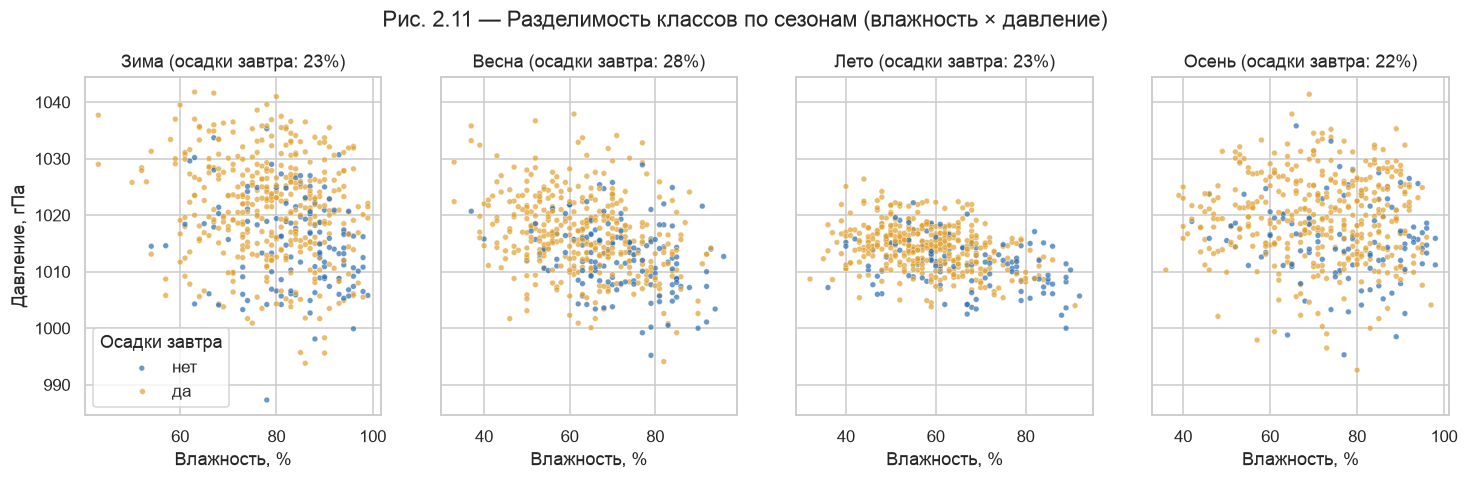

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, s in zip(axes, ["Зима", "Весна", "Лето", "Осень"]):
    d = df[df.season == s]
    sns.scatterplot(data=d.sample(min(500, len(d)), random_state=0), x="relative_humidity_2m_mean", y="pressure_msl_mean",
                    hue="rain_tomorrow", palette=[C_DRY, C_WET], s=14, alpha=0.7, ax=ax, legend=(s == "Зима"))
    ax.set_title(f"{s} (осадки завтра: {d.rain_tomorrow.mean():.0%})"); ax.set_xlabel("Влажность, %"); ax.set_ylabel("Давление, гПа")
axes[0].legend(title="Осадки завтра", labels=["нет", "да"])
fig.suptitle("Рис. 2.11 — Разделимость классов по сезонам (влажность × давление)", y=1.03)
save("fig_2_11_season_scatter")

**Интерпретация.** В пространстве двух признаков классы сильно перекрываются — **граница решений не линейная и не простая**. Кроме того, зависимость меняется по сезонам (например, зимой воздух почти всегда влажный, но дождь идёт не всегда). Вывод: модель должна получать информацию о сезоне, а нелинейные модели (Random Forest, Gradient Boosting), вероятно, будут иметь преимущество.

## 7. Сохранение предобработанного набора данных

Сохраняем набор с целевой переменной и простыми производными признаками. Полное построение признаков (лаги, скользящие средние, циклическое кодирование) выполняется на следующем этапе.

In [25]:
df_out = df.dropna(subset=["pressure_change"]).reset_index(drop=True)   # the first day has no pressure change
PROCESSED.parent.mkdir(parents=True, exist_ok=True)
df_out.to_csv(PROCESSED, index=False)
print(f"Сохранено: {PROCESSED.relative_to(ROOT)} — {df_out.shape[0]} строк x {df_out.shape[1]} столбцов")

Сохранено: data/processed/chisinau_daily_clean.csv — 4016 строк x 35 столбцов


## 8. Выводы EDA

1. **Данные** — 4016 пригодных дней (2015–2025), 26 метеопризнаков, без пропусков и физических несоответствий. Экстремальные значения — реальные события, их сохраняем.
2. **Целевая переменная** несбалансирована (~24 % дней с осадками) → метрики F1 / Recall / ROC-AUC и балансировка с помощью **SMOTE**.
3. **Сильная сезонность** температуры и частоты осадков (максимум в мае ≈ 32 %, минимум в августе ≈ 14 %) → месяц кодируется циклически ($\sin$, $\cos$).
4. **Инерционность** погоды (после дождливого дня вероятность дождя ≈ в 2.5 раза выше) даёт наивную базовую модель («завтра как сегодня»), с которой будем сравнивать ML-модели.
5. **Самые информативные предикторы:** сегодняшние осадки, давление и его изменение, облачность, влажность, дефицит точки росы, солнечное сияние, направление ветра (В–Ю → дождь, СЗ → сухо).
6. Высокая **мультиколлинеарность** между группами признаков → отбор признаков / регуляризация / PCA.
7. Классы **перекрываются**, а зависимости меняются по сезонам → нелинейные границы решений; сравним линейные модели и ансамбли.
8. **Межгодовая изменчивость** (засушливые vs. дождливые годы) указывает на возможный *concept drift* → обоснование модуля **Streaming / RTAP** с периодическим переобучением.

**Следующие шаги:** построение признаков → базовые модели (логистическая регрессия, Random Forest, Gradient Boosting) → SMOTE, Noise, Bias, Decision Boundaries → Streaming и RTAP.